In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load the datasets
sales = pd.read_csv("../data/processed/online_retail_cleaned.csv", parse_dates=["InvoiceDate"])
returns = pd.read_csv("../data/processed/online_retail_returns.csv", parse_dates=["InvoiceDate"])

In [3]:
# 1) Number of rows, invoices, and identified customers
identified = sales[sales["CustomerID"] != -1]
print("Rows:", f"{len(sales):,}")
print("Invoices:", f"{sales['InvoiceNo'].nunique():,}")
print("Identified customers:", f"{identified['CustomerID'].nunique():,}")

# 2) Proportion of rows and revenue from unidentified customers (CustomerID == -1)
no_id = sales["CustomerID"] == -1
print(f"CustomerID == -1: {no_id.mean():.1%} of rows, "
      f"{sales.loc[no_id, 'TotalPrice'].sum() / sales['TotalPrice'].sum():.1%} of revenue")

# 3) date range of the dataset
print("Date range:", sales["InvoiceDate"].min(), "->", sales["InvoiceDate"].max())

# 4) largest sales by TotalPrice
cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "InvoiceDate", "TotalPrice"]
print(sales.nlargest(5, "TotalPrice")[cols])

# 5) Combine returns: C-invoices vs. non-C invoices
returns["IsCInvoice"] = returns["InvoiceNo"].astype(str).str.startswith("C")
print(returns["IsCInvoice"].value_counts())

Rows: 522,537
Invoices: 19,773
Identified customers: 4,334
CustomerID == -1: 25.1% of rows, 14.7% of revenue
Date range: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00
        InvoiceNo StockCode                          Description  Quantity  \
521070     581483     23843          PAPER CRAFT , LITTLE BIRDIE     80995   
59407      541431     23166       MEDIUM CERAMIC TOP STORAGE JAR     74215   
214408     556444     22502       PICNIC BASKET WICKER 60 PIECES        60   
335866     567423     23243  SET OF TEA COFFEE SUGAR TINS PANTRY      1412   
50697      540815     21108   FAIRY CAKE FLANNEL ASSORTED COLOUR      3114   

        UnitPrice  CustomerID         InvoiceDate  TotalPrice  
521070       2.08       16446 2011-12-09 09:15:00   168469.60  
59407        1.04       12346 2011-01-18 10:01:00    77183.60  
214408     649.50       15098 2011-06-10 15:28:00    38970.00  
335866       5.06       17450 2011-09-20 11:05:00     7144.72  
50697        2.10       15749 2011-01-11 12:55:

In [4]:
cols = ["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "InvoiceDate", "TotalPrice"]

# 1) Largest rows of returns: Is there a pair of suspicious three rows there?
print(returns.nsmallest(5, "TotalPrice")[cols])

# 2) what are 474 rows without C?
non_c = returns[~returns["IsCInvoice"]]
print("Share with UnitPrice == 0:", (non_c["UnitPrice"] == 0).mean().round(3))
print("Share with CustomerID == -1:", (non_c["CustomerID"] == -1).mean().round(3))
print(non_c["StockCode"].value_counts().head(5))

# 3) Product vs. non-product returns (following the same Step 5 pattern)
is_product = returns["StockCode"].astype(str).str.match(r"^(?:\d{5}|DCGS)")
print(returns.groupby(is_product)["TotalPrice"].agg(["count", "sum"]))

     InvoiceNo  StockCode                     Description  Quantity  \
9718   C581484      23843     PAPER CRAFT , LITTLE BIRDIE    -80995   
1045   C541433      23166  MEDIUM CERAMIC TOP STORAGE JAR    -74215   
4143   C556445          M                          Manual        -1   
9484   C580605  AMAZONFEE                      AMAZON FEE        -1   
744    C540117  AMAZONFEE                      AMAZON FEE        -1   

      UnitPrice  CustomerID         InvoiceDate  TotalPrice  
9718       2.08       16446 2011-12-09 09:27:00  -168469.60  
1045       1.04       12346 2011-01-18 10:17:00   -77183.60  
4143   38970.00       15098 2011-06-10 15:31:00   -38970.00  
9484   17836.46          -1 2011-12-05 11:36:00   -17836.46  
744    16888.02          -1 2011-01-05 09:55:00   -16888.02  
Share with UnitPrice == 0: 1.0
Share with CustomerID == -1: 1.0
StockCode
85175     5
85172     4
21830     4
72802C    4
22423     3
Name: count, dtype: int64
           count        sum
StockCode    

## Analysis-ready data

In [5]:
# Convert CustomerID to nullable integer type
sales['CustomerID'] = sales['CustomerID'].astype('Int64').mask(sales['CustomerID'] == -1, pd.NA)

In [6]:
# Invoices that were fully reversed by a cancellation invoice within minutes.
# Evidence: each has a matching "C" invoice with the same CustomerID and the same
# total amount (168,469.60 / 77,183.60 / 38,970.00), issued 3-16 minutes later.
# Note: for 556444 the cancellation is a manual line (StockCode "M", Quantity -1),
# so it matches by amount, not by product or quantity.
# Assumption (not proven): these are data-entry corrections, not real customer returns.
# Found by inspecting the largest sales lines; no general matching was attempted.
REVERSED_INVOICES = [581483, 541431, 556444]

sales["IsReversedOrder"] = sales["InvoiceNo"].isin(REVERSED_INVOICES)

# value counts and total revenue of reversed orders
sales.groupby("IsReversedOrder")["TotalPrice"].agg(["count", "sum"])

,count,sum
IsReversedOrder,,
False,522534,9962596.12
True,3,284623.20


In [7]:
# Replace 'EIRE' with 'Ireland' in the Country column
returns['Country'] = returns['Country'].replace('EIRE', 'Ireland')

In [8]:
# Categorize return types based on StockCode and IsCInvoice
cond_product_cancel = returns["StockCode"].astype(str).str.match(r"^(?:\d{5}|DCGS)") & returns["IsCInvoice"]
cond_non_product_cancel = ~returns["StockCode"].astype(str).str.match(r"^(?:\d{5}|DCGS)") & returns["IsCInvoice"]

conditions = [cond_product_cancel,
               cond_non_product_cancel]

choices = ["product_cancellation",
           "non_product_cancellation"]

returns["ReturnType"] = np.select(conditions, choices, default="stock_adjustment")

In [9]:
returns.groupby("ReturnType")["TotalPrice"].agg(["count", "sum"])

,count,sum
ReturnType,,
non_product_cancellation,583,-418078.57
product_cancellation,8668,-475901.16
stock_adjustment,474,0.00


# Phase 2: Sales Trends Over Time

**Business question:** How do revenue, order volume, and average order value change over time, and when are the peak and slow periods?

## KPI definitions

| KPI | Definition |
|---|---|
| Revenue | Sum of `TotalPrice` over product lines in the sales data (excludes shipping, fees, and manual entries) |
| Orders | Number of distinct `InvoiceNo` (an invoice is one order; a row is only one product line) |
| Average order value (AOV) | Revenue ÷ Orders |

## Scope and caveats

- Three invoices flagged `IsReversedOrder` (about 2.8% of revenue) are excluded from trend figures, because each was cancelled within minutes by a matching "C" invoice.
- The data ends on 2011-12-09, so **December 2011 is a partial month** and must not be compared directly with December 2010.
- Cancellations and returns are not netted against sales here. They are analyzed separately in the returns section.
- Findings describe patterns in this dataset only. Seasonality is based on a single year, so it cannot be separated from one-off effects.

## Plan

1. Monthly revenue, orders, and AOV
2. Weekday and hour-of-day patterns
3. Short summary for a non-technical reader

In [10]:
# 1. Filtering rows where the order is not cancelled, and creating a 'Month' column
sales_filtered = sales[~sales["IsReversedOrder"]].copy()
sales_filtered['Month'] = sales_filtered['InvoiceDate'].dt.to_period('M')

# 2. Grouping by 'Month' and calculating revenue and number of orders
monthly_summary = sales_filtered.groupby('Month').agg(
    Revenue=('TotalPrice', 'sum'),
    Orders=('InvoiceNo', 'nunique')
).reset_index()

# Calculating Average Order Value (AOV)
monthly_summary['AOV'] = monthly_summary['Revenue'] / monthly_summary['Orders']

monthly_summary

,Month,Revenue,Orders,AOV
0,2010-12,775638.36,1550,500.411845
1,2011-01,593196.64,1080,549.256148
2,2011-02,507799.87,1093,464.592745
3,2011-03,689833.51,1440,479.051049
4,2011-04,515377.99,1235,417.310113
5,2011-05,739953.00,1668,443.616906
6,2011-06,698588.98,1524,458.391719
7,2011-07,688219.34,1452,473.980262
8,2011-08,724216.50,1339,540.863704
9,2011-09,1028320.38,1818,565.632772


In [11]:
# convert Month column to string (so that matplotlib can display it)
months = monthly_summary['Month'] = monthly_summary['Month'].astype(str)
revenue = monthly_summary['Revenue']
aov = monthly_summary['AOV']

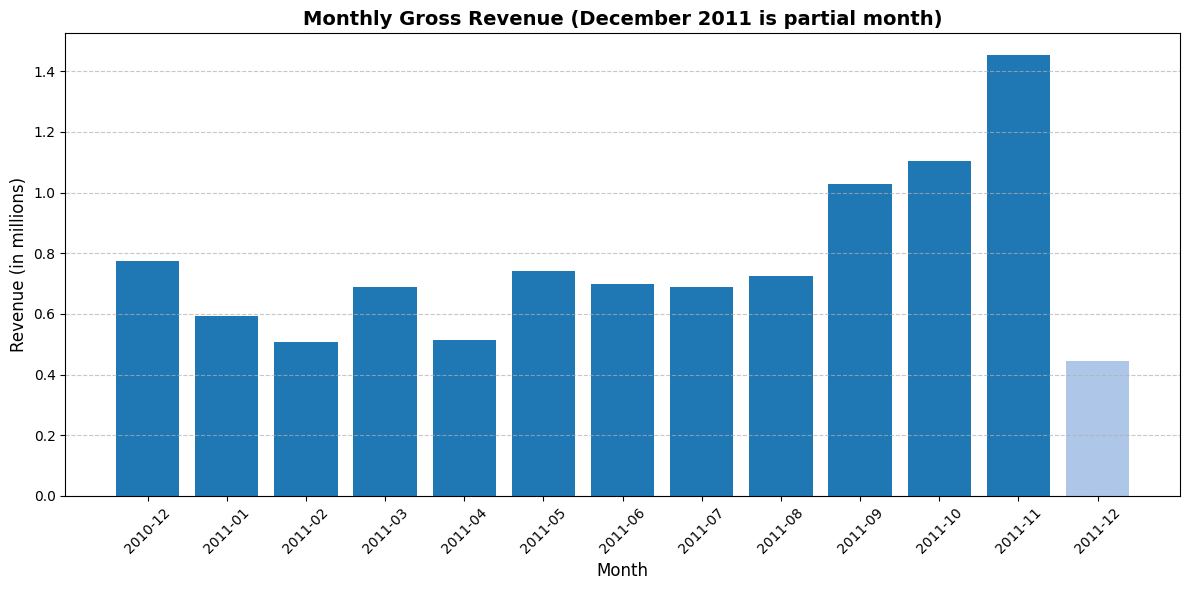

In [12]:
# make color list: all months are blue except last month (December 2011) gray or lighter
colors = ['#1f77b4'] * (len(monthly_summary) - 1) + ['#aec7e8']

plt.figure(figsize=(12, 6))
plt.bar(months, revenue/ 1e6, color=colors)

plt.title('Monthly Gross Revenue (December 2011 is partial month)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Revenue (in millions)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Revenue was relatively flat from January to August 2011, at roughly 0.5–0.75M per month, then rose sharply: 1.03M in September, 1.10M in October, and 1.45M in November, about twice August’s level. This is consistent with year-end gift-season buying, but with only one year of data we cannot separate seasonality from one-off effects. December 2011 (light bar) covers only nine days and should not be read as a decline.

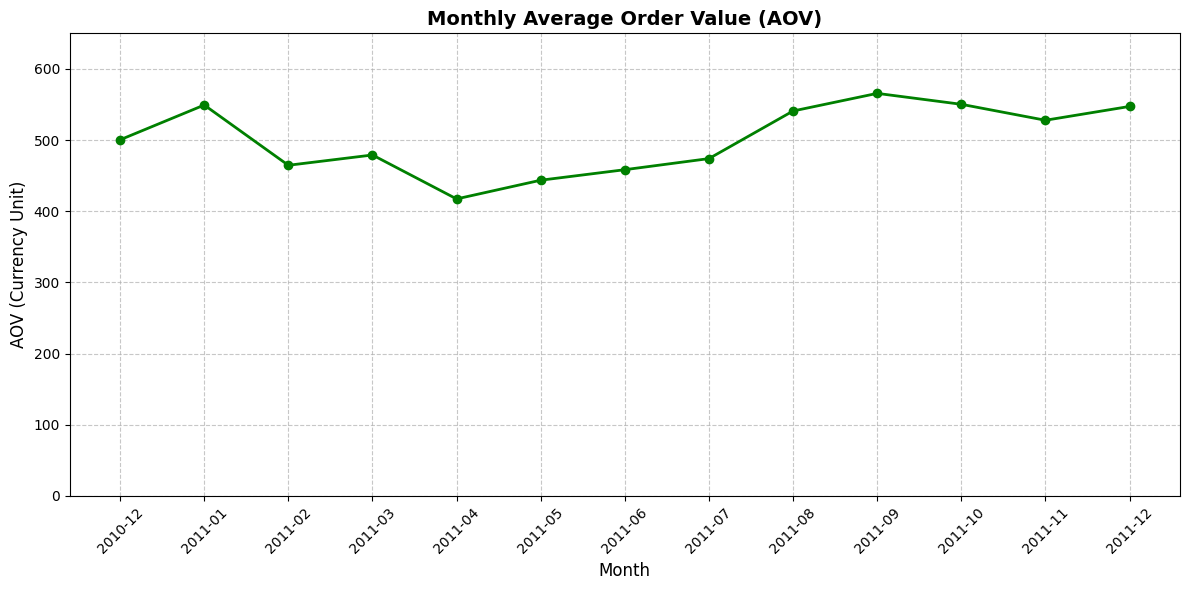

In [13]:
plt.figure(figsize=(12, 6))
plt.plot(months, aov, marker='o', color='green', linewidth=2, markersize=6)

plt.title('Monthly Average Order Value (AOV)', fontsize=14, fontweight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('AOV (Currency Unit)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.7)
plt.ylim(0, 650)

plt.tight_layout()
plt.show()

Average order value (AOV) fell from about 549 in January to a low of 417 in April, then recovered to a peak of 566 in September (+36% from the April low), and stayed between 528 and 550 afterwards. Because revenue = orders × AOV, the September–November revenue surge came mainly from more orders, not larger ones: AOV in November (528) was slightly below August (541), while orders roughly doubled (1,339 to 2,751). AOV is a mean, so we cannot tell whether its changes come from more items per order, higher-priced items, or a few very large orders; that needs a breakdown by order size.

In [14]:
monthly_summary[["Revenue", "Orders", "AOV"]].pct_change()

,Revenue,Orders,AOV
0,NaN,NaN,NaN
1,-0.235215,-0.303226,0.097608
2,-0.143960,0.012037,-0.154142
3,0.358475,0.317475,0.031120
4,-0.252895,-0.142361,-0.128882
5,0.435748,0.350607,0.063039
6,-0.055901,-0.086331,0.033305
7,-0.014844,-0.047244,0.034007
8,0.052305,-0.077824,0.141110
9,0.419907,0.357730,0.045795


In 9 of the 11 full month-over-month comparisons, revenue moved in the same direction as the number of orders. The exceptions were February, when AOV fell 15% while orders stayed flat (revenue down), and August, when AOV rose 14% while orders fell 8% (revenue up slightly). Orders are far more volatile than AOV (average absolute monthly change of about 20% versus 7%), so most revenue swings in this data come from order volume. With only one year of data we cannot tell whether this pattern is typical, and we do not know what caused the two exceptions.

## 2.2 Weekday and Hour-of-Day Patterns

**Business question:** On which days and at which hours do orders and revenue concentrate?

- Metrics: orders (distinct `InvoiceNo`) and revenue (sum of `TotalPrice`), excluding the three reversed invoices.
- Timestamps come from `InvoiceDate`; the time zone is not documented, so hours are as recorded.
- Patterns describe this dataset only (one year, mostly one country).

In [15]:
# Table of the days of the week in the correct order (Monday to Sunday)
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

day_summary = sales_filtered.groupby('DayOfWeek').agg(
    Revenue=('TotalPrice', 'sum'),
    Orders=('InvoiceNo', 'nunique')
).reindex(days_order)

day_summary['AOV'] = day_summary['Revenue'] / day_summary['Orders']

# Daily Schedule (Store Operating Hours)
hourly_summary = sales_filtered.groupby('Hour').agg(
    Revenue = ('TotalPrice', 'sum'),
    Orders = ('InvoiceNo', 'nunique')
).reindex()

# Display tables
display(day_summary, hourly_summary)

,Revenue,Orders,AOV
DayOfWeek,,,
Monday,1682860.52,3076.0,547.093797
Tuesday,2007831.72,3508.0,572.357959
Wednesday,1782348.34,3667.0,486.050815
Thursday,2131596.38,4209.0,506.437724
Friday,1559647.66,3107.0,501.978648
Saturday,NaN,NaN,NaN
Sunday,798311.50,2203.0,362.374716


,Revenue,Orders
Hour,,
6,4.25,1
7,30469.21,29
8,279297.68,565
9,787240.56,1470
10,1324540.43,2338
11,1196787.55,2373
12,1412921.32,3205
13,1220350.18,2730
14,1119658.12,2419


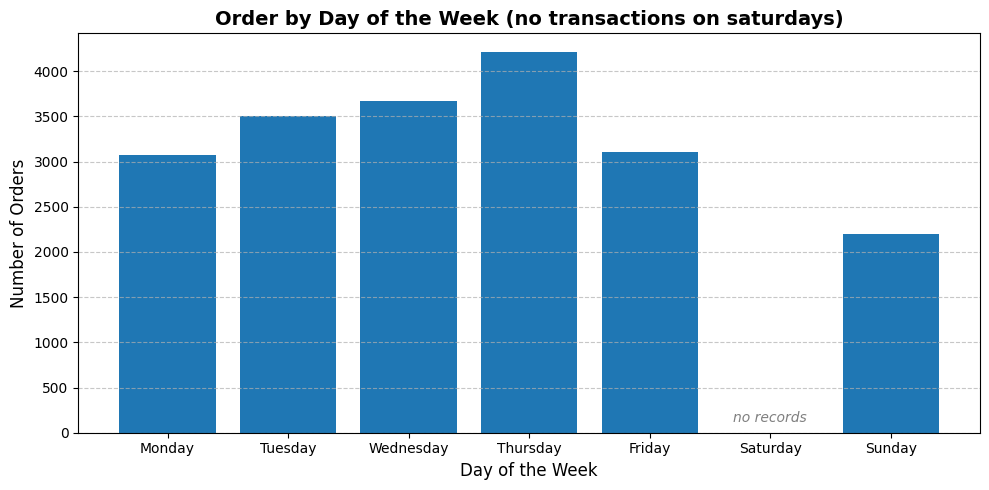

In [16]:
# Fixed weekday order; missing days become NaN
orders_by_day = day_summary['Orders'].reindex(days_order)

# Zero-fill only for drawing; day_summary itself is not modified
plot_values = orders_by_day.fillna(0)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(days_order, plot_values, color='#1f77b4')

# Make the missing day explicit instead of leaving an unexplained empty slot
saturday_pos = days_order.index('Saturday')
ax.text(saturday_pos, plot_values.max() * 0.02, "no records", ha='center', va='bottom', color='gray', style='italic')

ax.set_title('Order by Day of the Week (no transactions on saturdays)', fontsize=14, fontweight='bold')
ax.set_xlabel('Day of the Week', fontsize=12)
ax.set_ylabel('Number of Orders', fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Orders rise from 3,076 on Mondays to a peak of 4,209 on Thursdays (about 21% of all orders), then fall to 3,107 on Fridays. Sundays are the weakest day: 2,203 orders (about 11%), and their average order value (about 362) is roughly 25–35% below the other days (about 486–572), so Sunday orders are both fewer and smaller. No transactions are recorded on Saturdays in either the sales or the returns data, which suggests the business was closed or did not record transactions that day; this cannot be confirmed from the data.

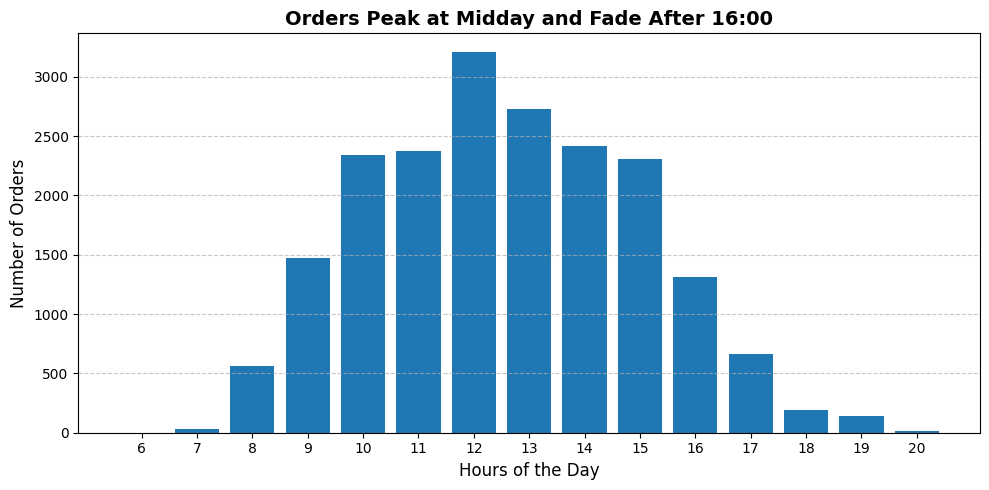

In [17]:
hours = hourly_summary.index.astype(str)

fig ,ax = plt.subplots(figsize=(10, 5))
ax.bar(hours, hourly_summary['Orders'], color='#1f77b4')

ax.set_title('Orders Peak at Midday and Fade After 16:00', fontsize=14, fontweight='bold')
ax.set_xlabel('Hours of the Day', fontsize=12)
ax.set_ylabel('Number of Orders', fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Orders are recorded from the 06:00 hour to the 20:00 hour, with a peak at 12:00 (3,205 orders). About 78% of orders fall between 10:00 and 15:59, so activity is concentrated in the middle of the working day. The timestamps have no documented time zone; since about 91% of raw rows come from the UK the times are likely UK local time, but this is not confirmed.

## 2.3 Short summary for a non-technical reader:

 Sales rise sharply in autumn: November revenue (about 1.45M) was roughly double August’s, and this came almost entirely from more orders, not from larger ones. Orders are concentrated midweek (Tuesday to Thursday) and between 10:00 and 15:59 (about 78% of orders), while Sundays are the weakest day, with fewer and smaller orders. These patterns suggest planning staffing, stock, and delivery capacity around the autumn peak and the midweek daytime hours. This is based on a single year of data, so we cannot tell whether the autumn peak repeats every year.